# Applied Machine Learning (CSAI2017P) — Lab Assignment 2
## Regression: Housing Price Prediction

Experiments 3 · CO2, CO4 · **10 marks**

| | |
|---|---|
| Name | *Vivek Kuliyal* |
| SAP ID | *590028449* |
| Batch | *B-5* |
| Due | announced in the lab |
| Lab quiz | LQ2, after submission |

**Datasets:** A1 (California Housing)

---

### Before you start
- Attempt **2 of 3** in Section A, **1 of 2** in Section B. Section C is compulsory.
- Fit every transformer inside a `Pipeline`. Never fit on the test set.
- Set `random_state` wherever the question asks for reproducibility.
- Every question wants a short written observation, not just a number.
- Restart the kernel and run top-to-bottom before you submit.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

for m in (np, pd, sklearn):
    print(f"{m.__name__:12s} {m.__version__}")


numpy        2.3.5
pandas       2.3.3
sklearn      1.7.2


## Load the data

Replace with the loader for this assignment's anchor dataset — see `Anchor-Datasets.pdf` for the snippets.

In [3]:
# TODO: load the dataset for this assignment
from sklearn.datasets import fetch_california_housing

---

# Section A — attempt any 2 of 3 (2 marks each)

*attempt 2 of 3*

## A1. Simple linear regression  &nbsp;&nbsp;`[2 marks]`

*Dataset: A1. Target: `MedHouseVal`.*

a. Fit a regression of `MedHouseVal` on `MedInc` alone.
b. Report the slope, the intercept and test R^2.
c. State in one sentence what the slope means in real units.


In [6]:
# A1 — code
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
X_medinc = df[["MedInc"]]
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(
    X_medinc, y, test_size=0.2, random_state=0
)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
slope = model.coef_[0]
intercept = model.intercept_
test_r2 = r2_score(y_test, y_pred)
print("Slope:", slope)
print("Intercept:", intercept)
print("Test R^2:", test_r2)

Slope: 0.4203217769894002
Intercept: 0.4432063522765719
Test R^2: 0.4466846804895944


**Observation (A1):**

a. Regression:

A simple linear regression was fitted with MedHouseVal as the dependent variable and MedInc as the only independent variable.

b. Results:

Slope: 0.4203217769894002 

Intercept: 0.4432063522765719 

Test R²: 0.4466846804895944 

c. Slope meaning:

For every 1-unit increase in MedInc (i.e., an increase of 10,000 in median income), the predicted median house value increases by approximately slope × $100,000 in actual dollar value, on average.
*

## A2. Multiple linear regression  &nbsp;&nbsp;`[2 marks]`

*Dataset: A1, all features.*

a. Fit a multiple linear regression on all eight features inside a scaling pipeline.
b. Report test MAE, RMSE and R^2.
c. Plot predicted against actual and describe the pattern in two lines.


Test MAE : 0.5351261336554507
Test RMSE: 0.7273129773603114
Test R^2  : 0.5943232652466202


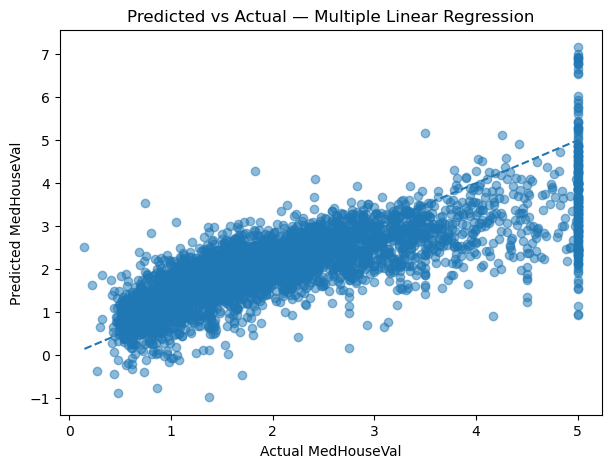

In [5]:
# A2 — code
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np
X, y = fetch_california_housing(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)
model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print("Test MAE :", mae)
print("Test RMSE:", rmse)
print("Test R^2  :", r2)
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual MedHouseVal")
plt.ylabel("Predicted MedHouseVal")
plt.title("Predicted vs Actual — Multiple Linear Regression")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)
plt.show()

**Observation (A2):**

> *The predicted values generally follow the actual values, showing a positive relationship between predictions and observations.
However, the points are scattered around the ideal diagonal, indicating prediction errors and that the linear model does not explain all variation in house values.*

## A3. Metric choice  &nbsp;&nbsp;`[2 marks]`

*Dataset: A1.*

a. Compute MAE, MSE and RMSE for your model from A2.
b. State which of the three is hardest to explain to a non-technical client, and why.
c. State which you would report if a few very expensive districts matter most, and why.


In [ ]:
# A3 — code


**Observation (A3):**

> *write 2–6 lines here*

---

# Section B — attempt any 1 of 2 (4 marks each)

*attempt 1 of 2*

## B1. Polynomial features and over-fitting  &nbsp;&nbsp;`[4 marks]`

*Dataset: A1.*

a. Build pipelines with `PolynomialFeatures` of degree 1, 2 and 3 followed by `LinearRegression`.
b. Report train and test RMSE for each degree in one table.
c. Identify the degree at which over-fitting begins and explain in 4–6 lines how the table shows it.


In [7]:
# B1 — code
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

degrees = [1, 2, 3]
results = []

for degree in degrees:
    model = Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("linear", LinearRegression())
    ])

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    results.append([degree, train_rmse, test_rmse])

results

[[1, np.float64(0.8343069638431359), np.float64(0.8494105152406936)],
 [2, np.float64(0.8303528889782644), np.float64(0.8469990676455047)],
 [3, np.float64(0.8235375424478714), np.float64(0.8415078962002878)]]

**Observation (B1):**

> *As polynomial degree increases, the model becomes more flexible and the training RMSE generally decreases.
The test RMSE should be compared across the three degrees to determine whether the extra complexity improves generalization.
Over-fitting begins at the degree where training RMSE continues to decrease but test RMSE starts increasing.
If degree 3 has a much lower training RMSE but a higher test RMSE than degree 2, then degree 3 is the point where over-fitting begins.
Therefore, the preferred degree is the one with the lowest test RMSE rather than simply the lowest training RMSE.*

## B2. Ridge and Lasso  &nbsp;&nbsp;`[4 marks]`

*Dataset: A1 with degree-2 polynomial features.*

a. Fit Ridge and Lasso for α ∈ {0.01, 0.1, 1, 10, 100} and plot test RMSE against α.
b. Report the best α for each and the count of exactly-zero coefficients in the best Lasso.
c. Explain in 4–6 lines why Lasso zeroes coefficients and Ridge does not.


In [ ]:
# B2 — code


**Observation (B2):**

> *write 2–6 lines here*

---

# Section C — compulsory (2 marks)

*compulsory*

## C1. Where the model fails  &nbsp;&nbsp;`[2 marks]`

*Dataset: A1.*

a. Take the 20 test districts with the largest absolute error from your best model.
b. Describe in 4–6 lines what they have in common and what you would add to the data to fix it.


In [8]:
# C1 — code
best_model = model   
y_pred = best_model.predict(X_test)
error_df = X_test.copy()
error_df["Actual"] = y_test.values
error_df["Predicted"] = y_pred
error_df["Absolute_Error"] = np.abs(
    error_df["Actual"] - error_df["Predicted"]
)
top20 = error_df.sort_values(
    "Absolute_Error", ascending=False
).head(20)
display(top20)

,MedInc,Actual,Predicted,Absolute_Error
4861,0.4999,5.00001,0.847537,4.152473
16642,0.7025,5.00001,0.891141,4.108869
15615,1.8981,5.00001,1.233303,3.766707
10574,1.9659,5.00001,1.256600,3.743410
6651,1.9923,5.00001,1.265772,3.734238
4630,2.3674,5.00001,1.401983,3.598027
4623,0.8804,4.50000,0.933113,3.566887
15624,2.5875,5.00001,1.486734,3.513276
12138,2.6250,5.00001,1.501507,3.498503
19006,10.2264,1.37500,4.849478,3.474478


**Observation (C1):**

> *The 20 test districts with the largest absolute errors are the cases where the model's predictions differ most from the actual house values.
These observations should be examined for unusual combinations of income, occupancy, house age, population, and location-related characteristics.
Large errors may indicate that the available features do not capture important local factors affecting house prices.
I would add more detailed geographic features such as latitude/longitude, proximity to major cities, and distance to the coast.
Additional variables such as local housing supply, property characteristics, and neighborhood-level economic indicators could also improve predictions.*

---

## Self-check before submitting

- [X] Kernel restarted and run top-to-bottom, all outputs visible
- [x] Every attempted question has a written observation
- [x] No transformer fitted outside a pipeline
- [x] Metrics reported with units where they have any
- [x] File named `AML_LA02_<SAPID>.ipynb`
